In [1]:
import numpy as np
import matplotlib.pyplot as plt
import IPython
from sklearn.decomposition import NMF
from scipy.io.wavfile import read, write
from scipy.signal import stft
import scipy

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
#Charger l'audio 
freqEchan1, audio1 = read('Fichiers sonores de test-20251203/piano_mix.wav')
t_audio1 = np.arange(len(audio1))/freqEchan1
IPython.display.Audio('Fichiers sonores de test-20251203/piano_mix.wav')

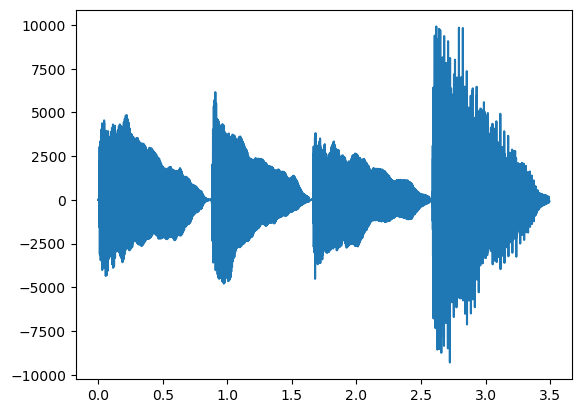

In [ ]:
plt.plot(t_audio1, audio1);

In [ ]:
#Short Time Fourier Transform
size = 2048
f, t, M = stft(audio1, freqEchan1, nperseg=size)
M = np.abs(M)

In [ ]:
#Decomposition en matrice dictionnaire et activation
model = NMF(n_components=3, max_iter=5000, beta_loss=2)
W = model.fit_transform(M)
H = model.components_

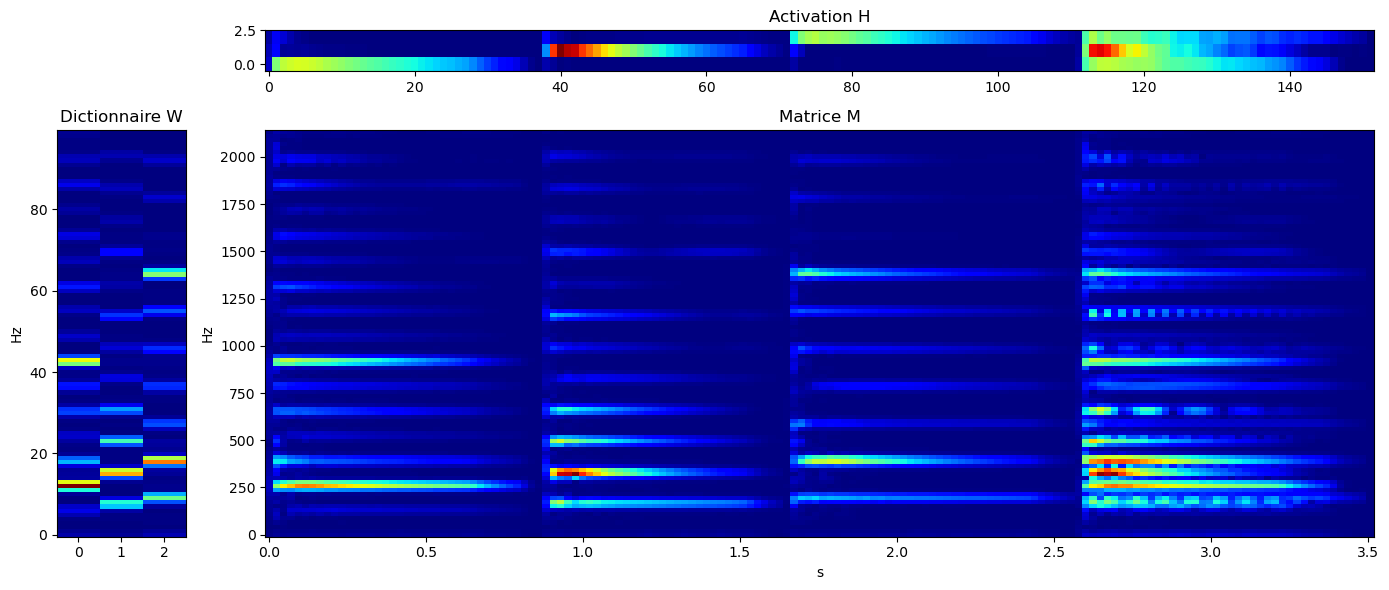

In [ ]:
freqScale = 100

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# Matrice Activation
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(H, aspect='auto', origin='lower',interpolation='nearest',cmap='jet')
ax_H.set_title("Activation H")

# Matrice Dictionnaire
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(W[:freqScale],aspect='auto', origin='lower', interpolation='nearest',cmap='jet')
ax_W.set_title("Dictionnaire W")
ax_W.set_ylabel("Hz")

# Matrice M
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.pcolormesh(t,f[:freqScale],np.abs(M)[:freqScale], shading='nearest',cmap='jet')
ax_V.set_title("Matrice M")
ax_V.set_xlabel("s")
ax_V.set_ylabel("Hz")

plt.tight_layout()
plt.show()

In [ ]:
#Reconstruction
matriceSource1 = np.outer(W[:,0],H[0,:])
matriceSource1 = np.where(np.abs(matriceSource1) >= np.max(matriceSource1)/20, matriceSource1, 0)
t_source1, source1 = scipy.signal.istft(matriceSource1, fs=freqEchan1, nperseg=size)

#Interpolation linéaire pour avoir la reconstruction de bonne longueur
interp = scipy.interpolate.interp1d(t_source1, source1, kind='linear', fill_value="extrapolate")
source1 = interp(t_audio1)

In [ ]:
#Reconstruction
matriceSource2 = np.outer(W[:,1],H[1,:])
matriceSource2 = np.where(np.abs(matriceSource2) >= np.max(matriceSource2)/20, matriceSource2, 0)
t_source2, source2 = scipy.signal.istft(matriceSource2, fs=freqEchan1, nperseg=size)

#Interpolation linéaire pour avoir la reconstruction de bonne longueur
interp = scipy.interpolate.interp1d(t_source2, source2, kind='linear', fill_value="extrapolate")
source2 = interp(t_audio1)

In [ ]:
#Reconstruction
matriceSource3 = np.outer(W[:,2],H[2,:])
matriceSource3 = np.where(np.abs(matriceSource3) >= np.max(matriceSource3)/20, matriceSource3, 0)
t_source3, source3 = scipy.signal.istft(matriceSource3, fs=freqEchan1, nperseg=size)

#Interpolation linéaire pour avoir la reconstruction de bonne longueur
interp = scipy.interpolate.interp1d(t_source3, source3, kind='linear', fill_value="extrapolate")
source3 = interp(t_audio1)

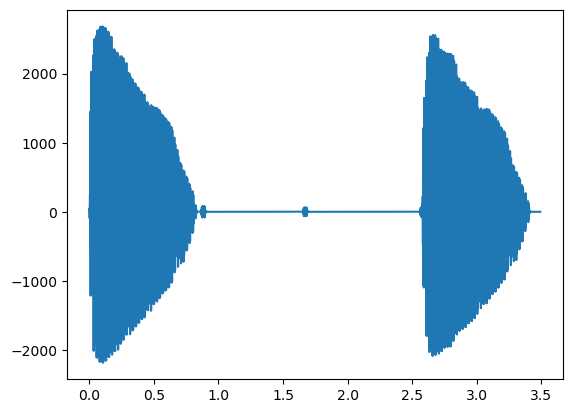

In [ ]:
plt.plot(t_audio1, source1);

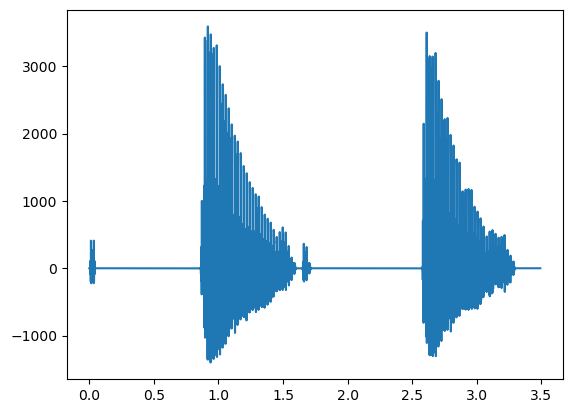

In [ ]:
plt.plot(t_audio1, source2);

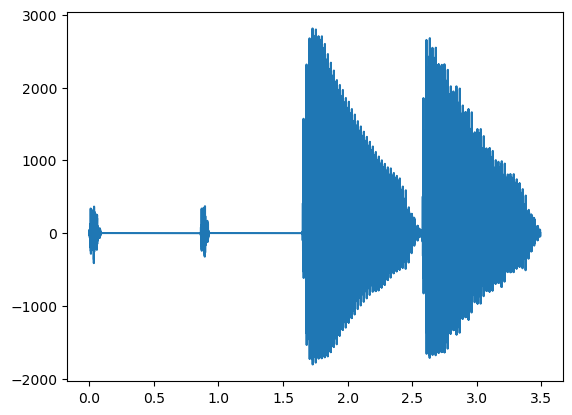

In [ ]:
plt.plot(t_audio1, source3);

In [ ]:
#Ecriture et lecture de la source reconstruit
write('source1.wav', rate=freqEchan1, data=source1.astype(np.int16))
IPython.display.Audio('source1.wav')

In [ ]:
write('source2.wav', rate=freqEchan1, data=source2.astype(np.int16))
IPython.display.Audio('source2.wav')

In [ ]:
write('source3.wav', rate=freqEchan1, data=source3.astype(np.int16))
IPython.display.Audio('source3.wav')